                                    PROJEKT ZALICZENIOWY - WIZUALIZACJA DANYCH
                                     Raport na podstawie danych 'pokemon.csv'
                                     Zespół: Piotr, Łukasz, Małgorzata Teślak

In [2]:
# Wczytanie bibliotek

import pandas as pd
import numpy as np
import skimpy as skim
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import boxcox

In [3]:
# Wczytanie danych z pliku CSV
dane = pd.read_csv('pokemon.csv')

In [4]:
skim.skim(dane)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 800    │ │ int64       │ 9     │                                                          │
│ │ Number of columns │ 13     │ │ string      │ 3     │                                                          │
│ └───────────────────┴────────┘ │ bool        │ 1     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column         ┃ NA   ┃ NA %   ┃ mean    ┃ sd      ┃ p0    ┃ p25     ┃ p50     ┃ p75     ┃ p100  ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━╇━━━━━━━━━┩  │
│ │       #        │    0 │      0 │   362.8 │   208.3 │     1 │   184.8 │   364.5 │   539.2 │   721 │ ▇▇▇▇▇▇  │  │
│ │     Total      │    0 │      0 │   435.1 │     120 │   180 │     330 │     450 │     515 │   780 │ ▂▇▇▇▃▁  │  │
│ │       HP       │    0 │      0 │   69.26 │   25.53 │     1 │      50 │      65 │      80 │   255 │   ▁▇▂   │  │
│ │     Attack     │    0 │      0 │      79 │   32.46 │     5 │      55 │      75 │     100 │   190 │  ▂▇▇▅▂  │  │
│ │    Defense     │    0 │      0 │   73.84 │   31.18 │     5 │      50 │      70 │      90 │   230 │  ▂▇▅▁   │  │
│ │    Sp. Atk     │    0 │      0 │   72.82 │   32.72 │    10 │   49.75 │      65 │      95 │   194 │  ▃▇▅▃▁  │  │
│ │    Sp. Def     │    0 │      0 │    71.9 │   27.83 │    20 │      50 │      70 │      90 │   230 │  ▅▇▃▁   │  │
│ │     Speed      │    0 │      0 │   68.28 │   29.06 │     5 │      45 │      65 │      90 │   180 │  ▃▇▇▅▁  │  │
│ │   Generation   │    0 │      0 │   3.324 │   1.661 │     1 │       2 │       3 │       5 │     6 │ ▇▅▇▆▇▃  │  │
│ └────────────────┴──────┴────────┴─────────┴─────────┴───────┴─────────┴─────────┴─────────┴───────┴─────────┘  │
│                                                      bool                                                       │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓  │
│ ┃ column                          ┃ true             ┃ true rate                      ┃ hist                 ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩  │
│ │            Legendary            │               65 │                          0.081 │        ▇    ▁        │  │
│ └─────────────────────────────────┴──────────────────┴────────────────────────────────┴──────────────────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓  │
│ ┃        ┃     ┃       ┃          ┃            ┃           ┃           ┃ chars per  ┃ words per ┃ total      ┃  │
│ ┃ column ┃ NA  ┃ NA %  ┃ shortest ┃ longest    ┃ min       ┃ max       ┃ row        ┃ row       ┃ words      ┃  │
│ ┡━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩  │
│ │  Name  │   0 │     0 │   Muk    │ CharizardM │ Aboma

In [5]:
# Wyświetlamy podstawowe informacje na temat typów kolumn z danymi
dane.info()
print('\n')
print('Rozmiar zbioru danych',dane.shape)

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   #           800 non-null    int64
 1   Name        800 non-null    str  
 2   Type 1      800 non-null    str  
 3   Type 2      414 non-null    str  
 4   Total       800 non-null    int64
 5   HP          800 non-null    int64
 6   Attack      800 non-null    int64
 7   Defense     800 non-null    int64
 8   Sp. Atk     800 non-null    int64
 9   Sp. Def     800 non-null    int64
 10  Speed       800 non-null    int64
 11  Generation  800 non-null    int64
 12  Legendary   800 non-null    bool 
dtypes: bool(1), int64(9), str(3)
memory usage: 89.3 KB


Rozmiar zbioru danych (800, 13)


In [6]:
#wyswietlimy pierwsze 5 wierszy danych
dane.head()

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


In [7]:
#sprawdzimy czy w danych występują wartości puste
dane.isna().any()

#             False
Name          False
Type 1        False
Type 2         True
Total         False
HP            False
Attack        False
Defense       False
Sp. Atk       False
Sp. Def       False
Speed         False
Generation    False
Legendary     False
dtype: bool

Jedyną zmienną w rozważanym zbiorze danych, która nie ma wszystkich wartości, jest zmienna Type 2. Sprawdzimy, czy pokemony, mające zdefiniowane 2 typy mają znacząco różne wartości pozostałych zmiennych niż pokemony, które mają tylko jeden typ.

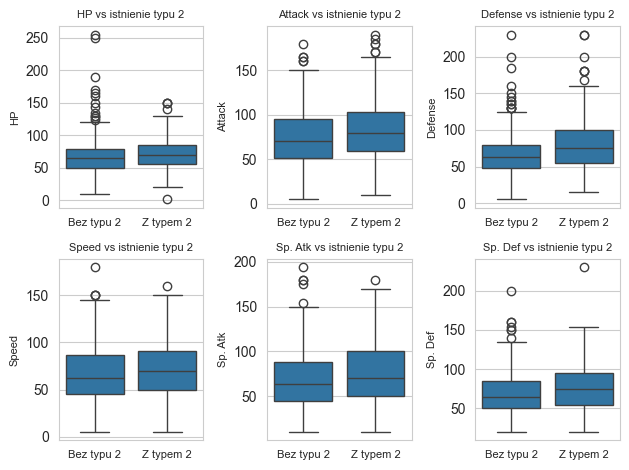

In [42]:
#pomocnicza kolumna, która będzie informować czy w danym wierszu istnieje wartość w kolumnie Type 2
dane['Type2Exists'] = dane['Type 2'].notna()
#lista zmiennych, które będziemy sprawdzać w zależności od istnienia typu 2
checking_variables = ["HP", "Attack", "Defense", "Speed", "Sp. Atk", "Sp. Def"]

for i in range(len(checking_variables)):
    checking_variable = checking_variables[i]
    plt.subplot(2, 3, i + 1)
    chart = sns.boxplot(data=dane, x="Type2Exists", y=checking_variable)
    plt.title(checking_variable + ' vs istnienie typu 2', fontsize=8)
    plt.xlabel("")
    plt.xticks([False, True], ["Bez typu 2", "Z typem 2"])
    plt.xticks(fontsize=8)
    plt.ylabel(checking_variable, fontsize=8)
    

plt.tight_layout()
plt.show()

48% pokemonów nie ma zdefiniowanego typu 2. Jest to reprezentatywna grupa danych/pokemonów, aby porównać ją z grupą pokemonów, które mają ów typ zdefiniowany. Z wykresów powyższych, porównujących rozkład takich zmiennych jak HP, Attack, Defense, Speed, Sp.Atk and Sp.Def versus posiadanie typu 2, możemy zauważyć, iż pokemony mające 2 typy wykazują się lekko większymi wartościami dla badanych cech.

Przyjrzymy się teraz w jakiej relacji są do siebie zmienne HP, Attack, Defense, Speed, Sp.Atk oraz Sp.Def. Chcemy sprawdzić, czy istnieje jakaś zależność między tymi zmiennymi.

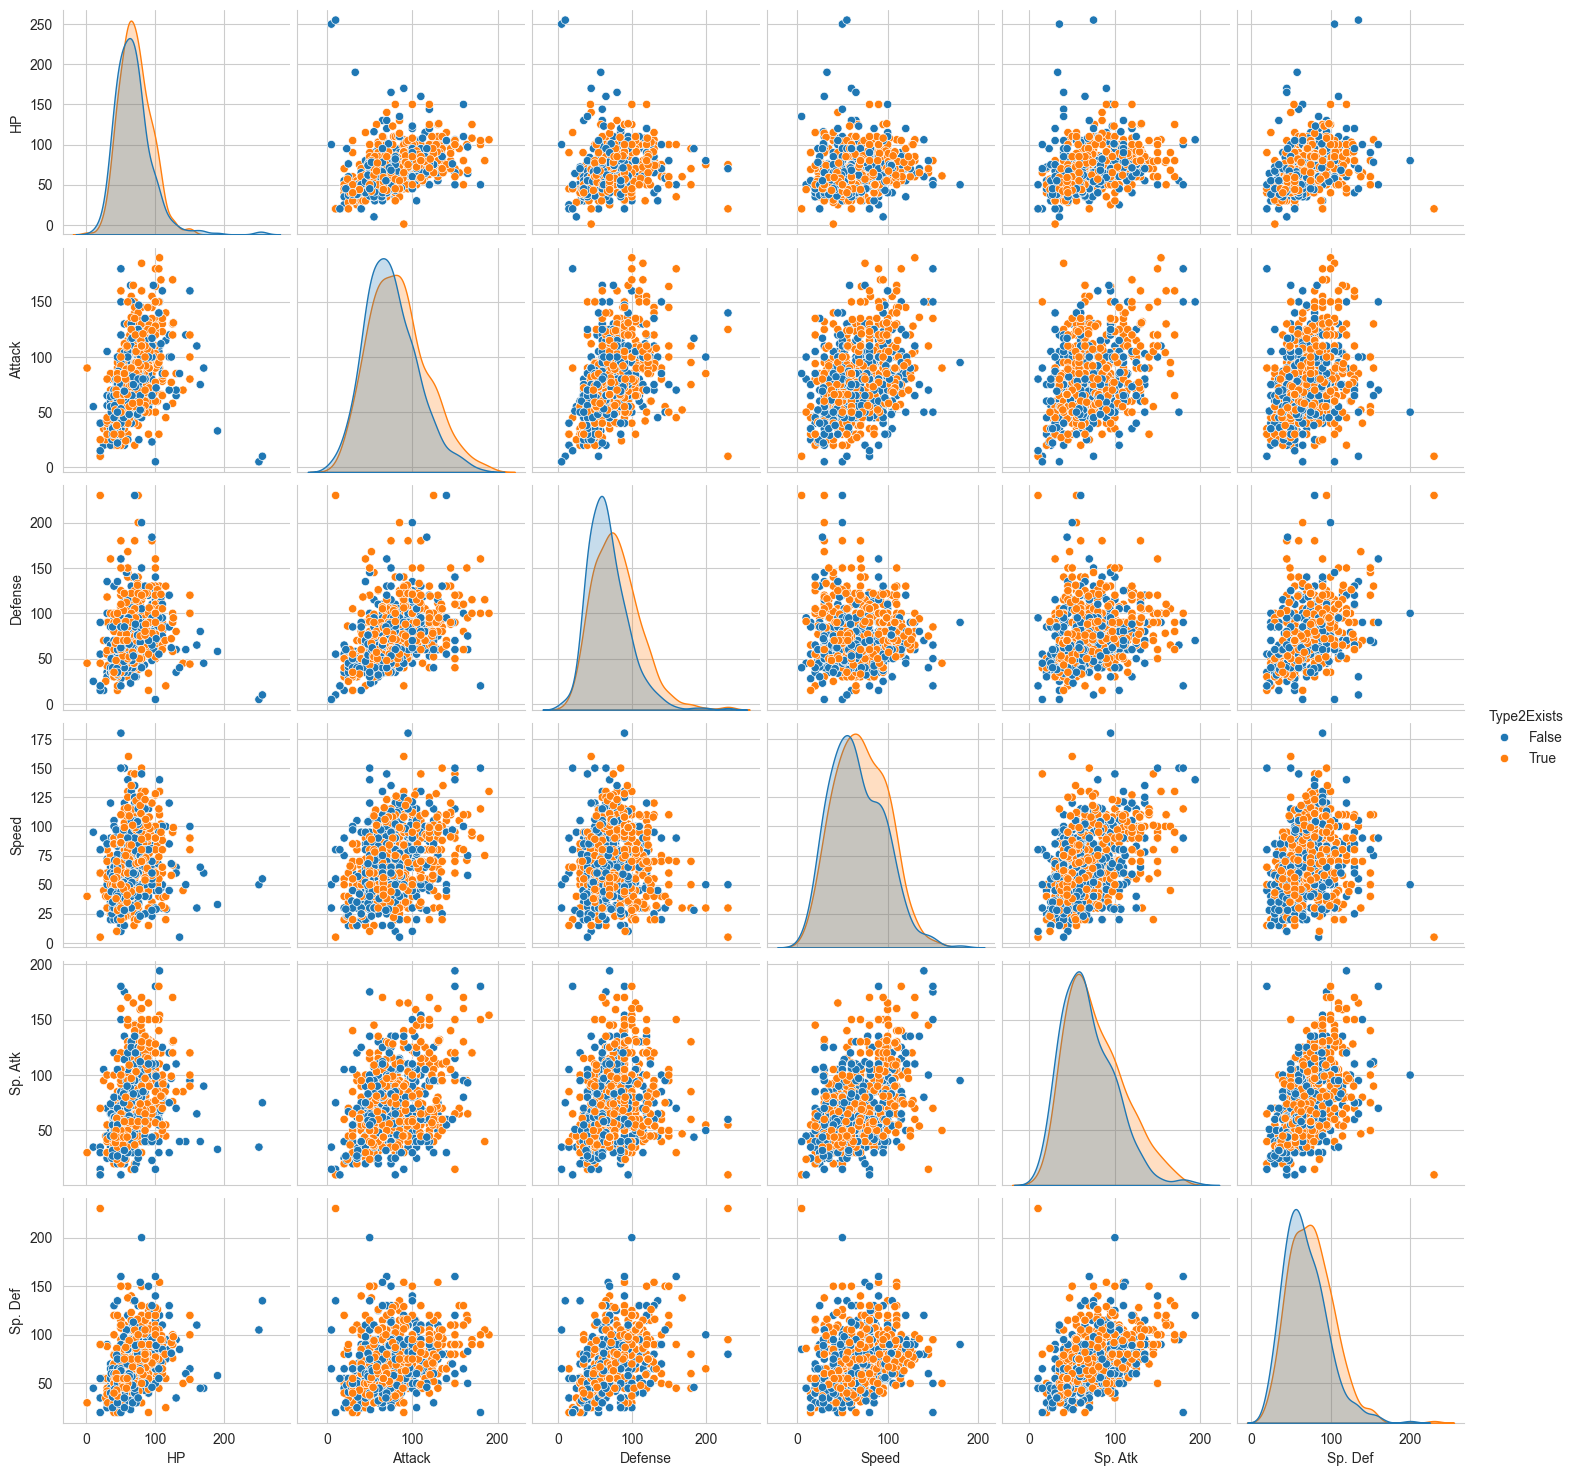

In [43]:
sns.pairplot(dane, vars=['HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def'], hue='Type2Exists')


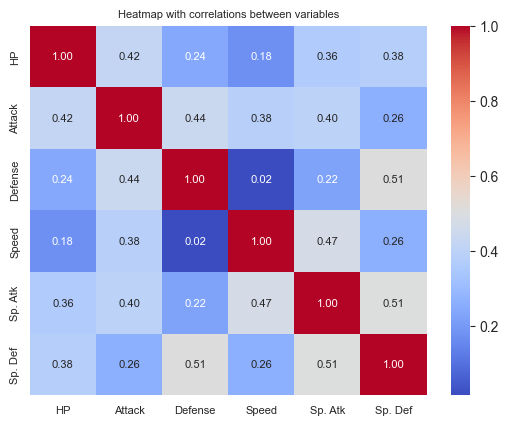

In [44]:
chart = sns.heatmap(dane[['HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def']].corr(), annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 8});
plt.title("Heatmap with correlations between variables", fontsize=8)
chart.set_xticklabels(chart.get_xticklabels(), fontsize=8)
chart.set_yticklabels(chart.get_yticklabels(), fontsize=8)
plt.show()

Z powyższej macierzy wykresów oraz z macierzy cieplnej z korelacją między zmiennymi wynika, iż nie ma silnej zależności między badanymi zmiennymi. Najsilniejsza wzajemna i dodatnia korelacja jest między Special Attack, a Special Defense. Zobaczymy teraz jak te zmienne wygladają per typ pokemona.

Zaczniemy od weryfikacji kształtu rozkładu badanych zmiennych: HP, Attack, Defense, Speed, Sp.Atk and Sp.Def

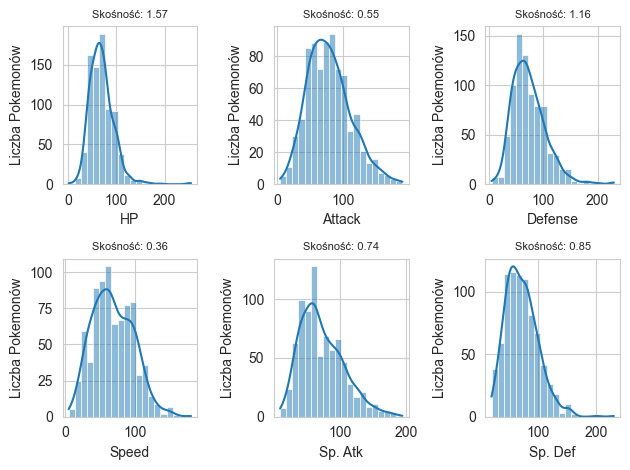

In [46]:
for i in range(len(checking_variables)):
    checking_variable = checking_variables[i]

    plt.subplot(2, 3, i + 1)
    sns.histplot(data=dane, x=checking_variable, bins=20, kde=True)

    skosnosc = dane[checking_variable].skew()

    plt.title(f"Skośność: {skosnosc:.2f}", fontsize = 8)
    plt.xlabel(checking_variable)
    plt.ylabel("Liczba Pokemonów")

plt.tight_layout()
plt.show()

W kształcie rozkładu każdej zmiennej widzimy lekką prawostronną skośność - dłuższe ogony z prawej strony. Potwierdzają to również dodatnie wartości wyliczonej statystyki skośności. Dlatego w przypadku budowania modelu na tych zmiennych Warto by było dokonać transformacji tych zmiennych, np. znormalizować je transformacją Boxa - Coxa.

In [ ]:
#zsumujemy wartości zmiennych wliczanych do Total w zależności od typu 1 Pokemona
zmienne_wplywajace_na_total = ["Total", "HP", "Attack", "Defense", "Speed", "Sp. Atk", "Sp. Def"]
zsumowane_dane = pd.DataFrame()
zsumowane_dane = dane.groupby('Type 1')[zmienne_wplywajace_na_total].sum().reset_index()
print(zsumowane_dane)

      Type 1  Total    HP  Attack  Defense  Speed  Sp. Atk  Sp. Def
0        Bug  26146  3925    4897     4880   4256     3717     4471
1       Dark  13818  2071    2740     2177   2361     2314     2155
2     Dragon  17617  2666    3588     2764   2657     3099     2843
3   Electric  19510  2631    3040     2917   3718     3961     3243
4      Fairy   7024  1260    1046     1117    826     1335     1440
5   Fighting  11244  1886    2613     1780   1784     1434     1747
6       Fire  23820  3635    4408     3524   3871     4627     3755
7     Flying   1940   283     315      265    410      377      290
8      Ghost  14066  2062    2361     2598   2059     2539     2447
9      Grass  29480  4709    5125     4956   4335     5425     4930
10    Ground  14000  2361    3064     2715   2045     1807     2008
11       Ice  10403  1728    1746     1714   1523     1861     1831
12    Normal  39365  7573    7200     5865   7012     5470     6245
13    Poison  11176  1883    2091     1927   178

In [30]:
for i in range(len(zmienne_wplywajace_na_total)):
    zmienna = zmienne_wplywajace_na_total[i]
    zsumowane_dane[f'{zmienna}_udzial'] = zsumowane_dane[zmienna] / zsumowane_dane['Total']
print(zsumowane_dane)

      Type 1  Total    HP  Attack  Defense  Speed  Sp. Atk  Sp. Def  \
0        Bug  26146  3925    4897     4880   4256     3717     4471   
1       Dark  13818  2071    2740     2177   2361     2314     2155   
2     Dragon  17617  2666    3588     2764   2657     3099     2843   
3   Electric  19510  2631    3040     2917   3718     3961     3243   
4      Fairy   7024  1260    1046     1117    826     1335     1440   
5   Fighting  11244  1886    2613     1780   1784     1434     1747   
6       Fire  23820  3635    4408     3524   3871     4627     3755   
7     Flying   1940   283     315      265    410      377      290   
8      Ghost  14066  2062    2361     2598   2059     2539     2447   
9      Grass  29480  4709    5125     4956   4335     5425     4930   
10    Ground  14000  2361    3064     2715   2045     1807     2008   
11       Ice  10403  1728    1746     1714   1523     1861     1831   
12    Normal  39365  7573    7200     5865   7012     5470     6245   
13    

<Axes: title={'center': 'Udział poszczególnych zmiennych w Total w zależności od typu 1 Pokemona'}, xlabel='Type 1'>

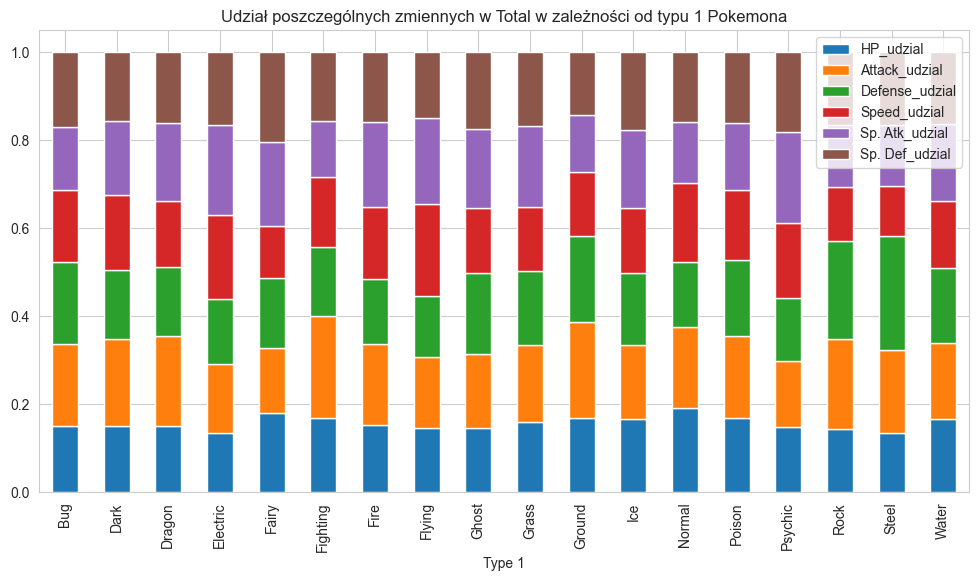

In [41]:
#narysujemy bar plot pokazujący udział poszczególnych zmiennych w Total w zależności od typu 1 Pokemona
zsumowane_dane_udzialy = zsumowane_dane[["Type 1", "HP_udzial", "Attack_udzial", "Defense_udzial", "Speed_udzial", "Sp. Atk_udzial", "Sp. Def_udzial"]]
zsumowane_dane_udzialy.plot(kind='bar', stacked=True, x='Type 1', title='Udział poszczególnych zmiennych w Total w zależności od typu 1 Pokemona', legend=True, figsize=(12, 6))

Z powyższego wykresu możemy wytypować pokemony, które charakteryzują się lepszą daną cechą niż pzoostałe pokemony. Dla przykładu możemy zauważyć, że pokemony typu Steel charaktreryzują się większą obrona/Defense niż pozostałe pokemony, a jednocześnie są jedne z wolniejszych pokemonów (mają jedną z niższych wartości Speed). Zobaczmy w formie tabelarycznej oraz na heatmapie jak rozkładają się średnie wartości tych zmiennych dla poszczególnych typów pokemonów.

In [66]:
srednie_dane = dane.groupby('Type 1')[zmienne_wplywajace_na_total].mean().reset_index()
from tabulate import tabulate
tabela_srednich = tabulate(srednie_dane, headers='keys', tablefmt='psql', showindex=True, numalign='center', stralign='center', )
print("Średnie wartości atrybutów dla różnych typów Pokémonów")
print(tabela_srednich)



Średnie wartości atrybutów dla różnych typów Pokémonów
+----+----------+---------+---------+----------+-----------+---------+-----------+-----------+
|    |  Type 1  |  Total  |   HP    |  Attack  |  Defense  |  Speed  |  Sp. Atk  |  Sp. Def  |
|----+----------+---------+---------+----------+-----------+---------+-----------+-----------|
| 0  |   Bug    | 378.928 | 56.8841 |  70.971  |  70.7246  | 61.6812 |  53.8696  |  64.7971  |
| 1  |   Dark   | 445.742 | 66.8065 | 88.3871  |  70.2258  | 76.1613 |  74.6452  |  69.5161  |
| 2  |  Dragon  | 550.531 | 83.3125 | 112.125  |  86.375   | 83.0312 |  96.8438  |  88.8438  |
| 3  | Electric | 443.409 | 59.7955 | 69.0909  |  66.2955  |  84.5   |  90.0227  |  73.7045  |
| 4  |  Fairy   | 413.176 | 74.1176 | 61.5294  |  65.7059  | 48.5882 |  78.5294  |  84.7059  |
| 5  | Fighting | 416.444 | 69.8519 | 96.7778  |  65.9259  | 66.0741 |  53.1111  |  64.7037  |
| 6  |   Fire   | 458.077 | 69.9038 | 84.7692  |  67.7692  | 74.4423 |  88.9808  |  72.211

Text(0.5, 1.0, 'Heatmapa średnich wartości atrybutów dla różnych typów Pokémonów')

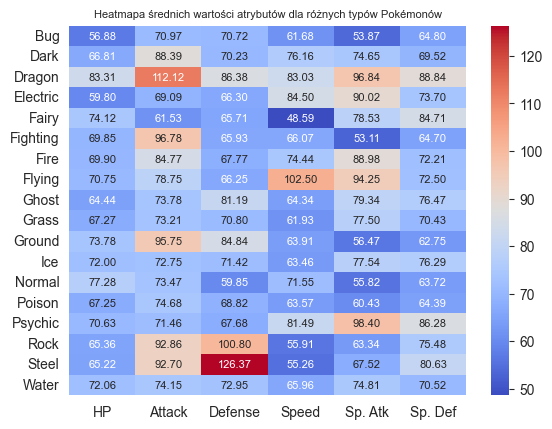

In [59]:
sns.heatmap(srednie_dane[['HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def']], yticklabels=srednie_dane['Type 1'], xticklabels=True, cmap='coolwarm', fmt=".2f", annot=True, annot_kws={"size": 8})
plt.title("Heatmapa średnich wartości atrybutów dla różnych typów Pokémonów", fontsize=8)

Heatmapa i tabela z danymi potwierdzają poprzedni wniosek. Dodatkowo możemy zauważyć, iż np. pokemony typu Fairy mają najmniejszą średnią prędkość.
Zobaczmy jak wygląda rozkład Defense per każdy typ pokemona. Sprawdzimy, czy czasem średnia Defense dla pokemonów typów Steel nie jest "ciągnięta" w górę przez duże wartości odstające.

<Axes: xlabel='Defense', ylabel='Type 1'>

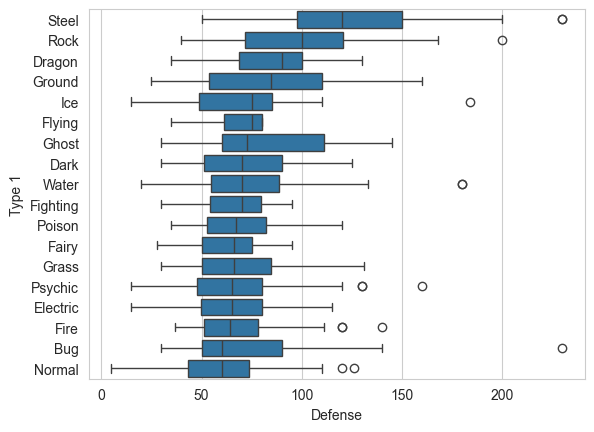

In [68]:
sns.boxplot(data=dane, y="Type 1", x="Defense", order=dane.groupby('Type 1')['Defense'].median().sort_values(ascending=False).index)

Mediana wartości obrony pokemonów typu Steel nie leży idealnie na środku, prawe pudełko jest bardziej wydłużone (dane prawostronie skośne), aczkolwiek nie jest to duża skośność, ponadto wąsy są w miarę symetryczne, zatem możemy wnioskować, że średnia wartość dla obrony dla tego typu pokemona, przedstawia całkiem realną wartość. Wykresy te potwierdzają, że faktycznie pokemony Steel mają największy atrybut obrony.

Zweryfikujmy jak poszczególne atrybuty przedstawiają się dla różnych generacji pokemonów.

Text(0.5, 1.0, 'Heatmapa średnich wartości atrybutów dla różnych generacji Pokemonów')

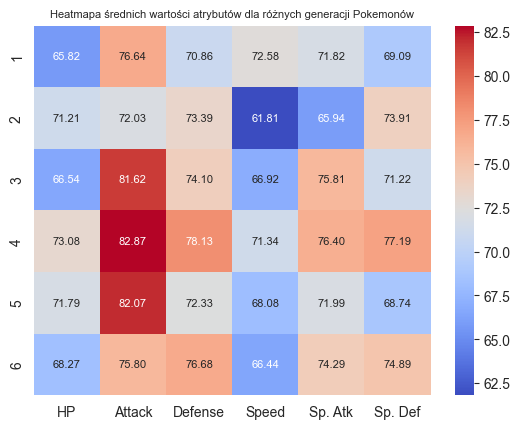

In [80]:
srednie_dane_per_generacja = dane.groupby('Generation')[zmienne_wplywajace_na_total].mean().reset_index()
sns.heatmap(srednie_dane_per_generacja[['HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def']], yticklabels=srednie_dane_per_generacja['Generation'], xticklabels=True, cmap='coolwarm', fmt=".2f", annot=True, annot_kws={"size": 8})
plt.title("Heatmapa średnich wartości atrybutów dla różnych generacji Pokemonów", fontsize=8)

Zauważamy, iż największa zmiana dotyczy atrybutu ataku dla pokemonów z generacji 3ciej, 4tej i 5tej.